In [1]:
# Gathers Data

import csv
import math
from pathlib import Path
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

ROOT = Path.cwd().resolve()
for _ in range(3):
    if (ROOT / "configs" / "base_akf.yaml").is_file():
        break
    if ROOT.parent == ROOT:
        break
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from data.crop_dataloader import SRC_H, SRC_W, CropDataset, _crop, _gaussian, _inside, _origin
from models.detection.cnn_detector.model import CNNDetector

# Trained run folder under saved_models/ (config.yaml + *.pt live here)
MODEL_DIR = "models/detection/cnn_detector/saved_models/cnn_detector"
# Last frame of the difference window. The split must include that game.
SPLIT = "train"
GAME, CLIP, FRAME = "game1", "Clip1", "0010.jpg"
# This view uses one fixed crop. The test cell draws size and placement from the training mix.
SIDE = 720
MODE = "centered"  # centered, offset, absent, random

run_dir = Path(MODEL_DIR)
if not run_dir.is_absolute():
    run_dir = ROOT / run_dir
with (run_dir / "config.yaml").open() as f:
    cfg = yaml.safe_load(f)

dataset_path = Path(cfg["paths"]["dataset"])
if not dataset_path.is_absolute():
    cfg["paths"]["dataset"] = str((ROOT / dataset_path).resolve())

dataset = CropDataset(cfg, split=SPLIT)


def window_index(game: str, clip: str, frame: str) -> int:
    for i, (paths, _) in enumerate(dataset.samples):
        last = paths[-1]
        if last.parent.parent.name == game and last.parent.name == clip and last.name == frame:
            return i
    raise KeyError(f"{game}/{clip}/{frame} is not in the {SPLIT} split")


def read_diffs(paths):
    grays = []
    for p in paths:
        gray = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        if gray is None:
            raise FileNotFoundError(p)
        if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
            gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
        grays.append(gray)
    return [
        (grays[i].astype(np.float32) - grays[i - 1].astype(np.float32)) / 255.0
        for i in range(1, len(grays))
    ]


def read_last_frame(path):
    bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(path)
    if bgr.shape[1] != SRC_W or bgr.shape[0] != SRC_H:
        bgr = cv2.resize(bgr, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)


def crop_window(diffs, lb, h, w, x0, y0, mode, sigma, amplitude):
    cropped = np.stack([_crop(d, x0, y0, h, w) for d in diffs], axis=0)
    vis = int(lb["visibility"])
    paint = vis > 0 and mode != "absent" and _inside(x0, y0, h, w, lb["x"], lb["y"])
    if paint:
        heat = _gaussian(h, w, lb["x"] - x0, lb["y"] - y0, sigma, amplitude)
    else:
        heat = np.zeros((h, w), dtype=np.float32)
    return cropped, heat, paint


index = window_index(GAME, CLIP, FRAME)
paths, label = dataset.samples[index]
h = w = int(SIDE)
x0, y0 = _origin(
    np.random.default_rng(0),
    MODE,
    label["x"],
    label["y"],
    h,
    w,
    center_jitter=dataset.center_jitter,
)
cropped, heat, inside = crop_window(
    read_diffs(paths), label, h, w, x0, y0, MODE, dataset.sigma, dataset.amplitude
)
frame = np.stack(
    [_crop(read_last_frame(paths[-1])[:, :, c].astype(np.float32) / 255.0, x0, y0, h, w) for c in range(3)],
    axis=-1,
)
x = torch.from_numpy(cropped)
gt = torch.from_numpy(heat)
print(
    f"{SPLIT}[{index}]  {' → '.join(p.name for p in paths)}\n"
    f"input {tuple(x.shape)}  heatmap {tuple(gt.shape)}  crop {w}×{h} at ({x0}, {y0})\n"
    f"vis={label['visibility']}  xy=({label['x']:.0f}, {label['y']:.0f})  inside={inside}"
)


train[8]  0008.jpg → 0009.jpg → 0010.jpg
input (2, 720, 720)  heatmap (720, 720)  crop 720×720 at (257, -122)
vis=1  xy=(593, 278)  inside=True


loaded models/detection/cnn_detector/saved_models/cnn_detector/cnn_detector.pt  cfg=cnn_detector  (cuda)


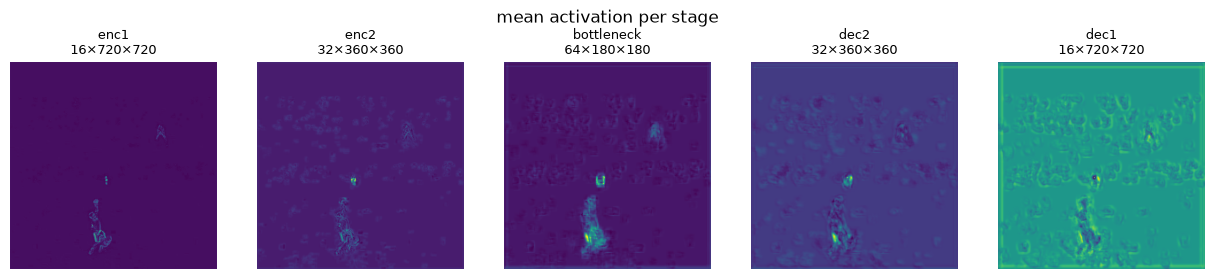

'layer = "bottleneck"\nn_channels = 8\nmaps = activations[layer][0, :n_channels].cpu().numpy()\nfig, axes = plt.subplots(1, n_channels, figsize=(2.2 * n_channels, 2.5))\nfor i, ax in enumerate(axes):\n    ax.imshow(maps[i], cmap="viridis")\n    ax.set_title(f"ch {i}", fontsize=9)\n    ax.axis("off")\nfig.suptitle(f"{layer} channels")\nfig.tight_layout()\nplt.show()'

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNNDetector(in_channels=int(cfg["model"]["num_diffs"])).to(device).eval()

checkpoint = next(run_dir.glob("*.pt"))
state = torch.load(checkpoint, map_location=device, weights_only=True)
model.load_state_dict(state["model"])
print(f"loaded {checkpoint.relative_to(ROOT)}  cfg={run_dir.name}  ({device})")

stages = ("enc1", "enc2", "bottleneck", "dec2", "dec1")
activations = {}


def capture(name):
    def hook(_module, _inputs, output):
        activations[name] = output.detach()

    return hook


handles = [getattr(model, name).register_forward_hook(capture(name)) for name in stages]
with torch.inference_mode():
    pred = model(x.unsqueeze(0).to(device))[0, 0].cpu()
for handle in handles:
    handle.remove()


fig, axes = plt.subplots(1, len(stages), figsize=(2.5 * len(stages), 2.8))
for ax, name in zip(axes, stages):
    act = activations[name][0]
    ax.imshow(act.mean(0).cpu().numpy(), cmap="viridis")
    channels, height, width = act.shape
    ax.set_title(f"{name}\n{channels}×{height}×{width}", fontsize=9)
    ax.axis("off")
fig.suptitle("mean activation per stage")
fig.tight_layout()
plt.show()

"""layer = "bottleneck"
n_channels = 8
maps = activations[layer][0, :n_channels].cpu().numpy()
fig, axes = plt.subplots(1, n_channels, figsize=(2.2 * n_channels, 2.5))
for i, ax in enumerate(axes):
    ax.imshow(maps[i], cmap="viridis")
    ax.set_title(f"ch {i}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"{layer} channels")
fig.tight_layout()
plt.show()"""


movement  flying
obscured  False  (visible)
in crop   True
true xy   (593, 278)
argmax    (335, 401) on 720×720  -> (592.0, 279.0)
distance  1.4 px


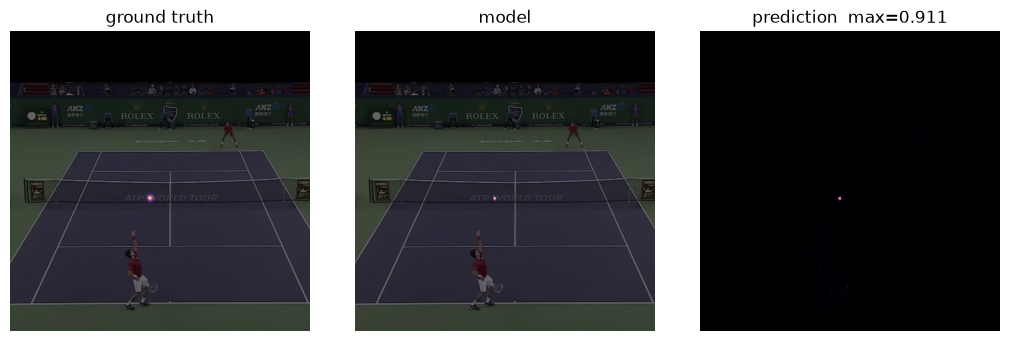

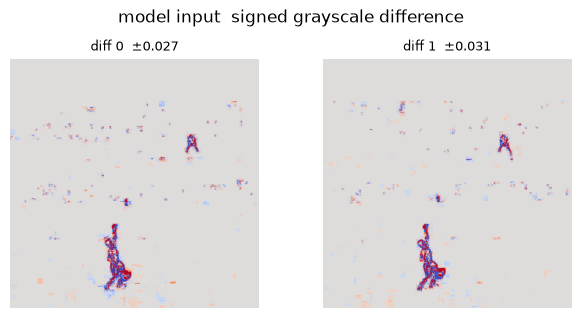

In [3]:
VISIBILITY = {0: "not in frame", 1: "visible", 2: "hard to see", 3: "occluded"}
MOVEMENT = {0: "flying", 1: "hit", 2: "bouncing"}

row = next(
    item
    for item in csv.DictReader((paths[-1].parent / "Label.csv").open(newline=""))
    if item["file name"] == paths[-1].name
)
visibility = int(row["visibility"] or 0)
status = int(row["status"] or 0)
true_x = float(row["x-coordinate"] or 0)
true_y = float(row["y-coordinate"] or 0)

heat = pred.numpy()
peak_y, peak_x = (int(i) for i in np.unravel_index(int(heat.argmax()), heat.shape))
pred_x = x0 + peak_x
pred_y = y0 + peak_y
distance = math.hypot(pred_x - true_x, pred_y - true_y)

print(
    f"movement  {MOVEMENT.get(status, status)}\n"
    f"obscured  {visibility == 3}  ({VISIBILITY.get(visibility, visibility)})\n"
    f"in crop   {inside}\n"
    f"true xy   ({true_x:.0f}, {true_y:.0f})\n"
    f"argmax    ({peak_x}, {peak_y}) on {w}×{h}  -> ({pred_x:.1f}, {pred_y:.1f})\n"
    f"distance  {distance:.1f} px"
)


def show_heatmap(ax, image, heat, title: str):
    ax.imshow(image)
    ax.imshow(heat, cmap="magma", alpha=0.6, vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
show_heatmap(axes[0], frame, gt.numpy(), "ground truth")
show_heatmap(axes[1], frame, pred.numpy(), "model")
axes[2].imshow(pred.numpy(), cmap="magma", vmin=0, vmax=1)
axes[2].set_title(f"prediction  max={float(pred.max()):.3f}")
axes[2].axis("off")
fig.tight_layout()
plt.show()

diffs = x.numpy()
fig, axes = plt.subplots(1, diffs.shape[0], figsize=(3.2 * diffs.shape[0], 3.2))
for i, ax in enumerate(np.atleast_1d(axes)):
    diff = diffs[i]
    vmax = max(float(np.percentile(np.abs(diff), 99)), 1.0 / 255.0)
    ax.imshow(diff, cmap="coolwarm", vmin=-vmax, vmax=vmax)
    ax.set_title(f"diff {i}  ±{vmax:.3f}", fontsize=9)
    ax.axis("off")
fig.suptitle("model input  signed grayscale difference")
fig.tight_layout()
plt.show()


game10/Clip1  n=314
game10/Clip10  n=164
game10/Clip11  n=37
game10/Clip12  n=579
game10/Clip2  n=130
game10/Clip3  n=186
game10/Clip4  n=45
game10/Clip5  n=63
game10/Clip6  n=290
game10/Clip7  n=140
game10/Clip8  n=63
game10/Clip9  n=47
test  n=2058  dist in source px  crops centered on the label  full = 1280×720
  crop    mean     std  median     p95    conf     vs 96
    48     1.9     2.3     1.4     3.6   0.795      -0.3
    96     2.2     4.4     1.4     3.6   0.794       0.0
   192     2.5     7.4     1.4     3.6   0.795       0.4
   384     3.4    14.5     1.4     3.6   0.795       1.3
   720     7.1    40.7     1.4     3.6   0.796       4.9
  full    11.4    64.6     1.4     4.0   0.796       9.2
paired gap (full - 96px) = 9.2 px  SE 1.40  median gap 0.0  full is higher on 13.3% of frames


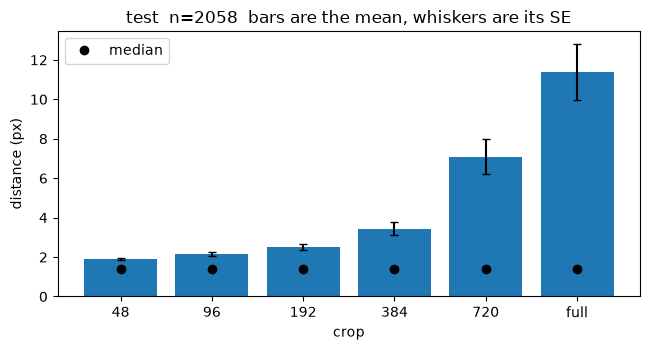

In [4]:
# Test split. Each labeled frame is scored at every crop size.
# Crops are centered on the label, so the ball is in the crop and size is the only change.
# 96px still covers a 48px step, past a typical frame-to-frame move.
# "full" is the 1280×720 frame.

SIZE_SPLIT = "test"
SMALL = 96
SIDES = [48, 96, 192, 384, 720]

size_ds = CropDataset(cfg, split=SIZE_SPLIT)
num_diffs = int(cfg["model"]["num_diffs"])
batch_size = int(cfg["train"]["batch_size"])
clips = {}
for paths, lb in size_ds.samples:
    if int(lb["visibility"]) <= 0:
        continue
    clips.setdefault(paths[-1].parent, []).append((paths, lb))


def read_gray(path):
    gray = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if gray is None:
        raise FileNotFoundError(path)
    if gray.shape[1] != SRC_W or gray.shape[0] != SRC_H:
        gray = cv2.resize(gray, (SRC_W, SRC_H), interpolation=cv2.INTER_AREA)
    return gray


def score_size(grays, items, h, w, center):
    n_items = len(items)
    dists = np.empty(n_items, np.float64)
    confs = np.empty(n_items, np.float64)
    bs = max(1, min(batch_size, int(8_000_000 / (h * w))))
    for start in range(0, n_items, bs):
        chunk = items[start : start + bs]
        crops = []
        origins = []
        for i, xy in chunk:
            if center:
                x0 = int(round(float(xy[0]) - w / 2))
                y0 = int(round(float(xy[1]) - h / 2))
            else:
                x0 = y0 = 0
            window = grays[i - num_diffs : i + 1]
            diffs = [
                (window[k].astype(np.float32) - window[k - 1].astype(np.float32)) / 255.0
                for k in range(1, len(window))
            ]
            crops.append(np.stack([_crop(d, x0, y0, h, w) for d in diffs], axis=0))
            origins.append((x0, y0))
        batch = torch.from_numpy(np.stack(crops)).to(device)
        with torch.inference_mode():
            heats = model(batch)[:, 0].detach().cpu().numpy()
        for j, ((_, xy), (x0, y0), heat) in enumerate(zip(chunk, origins, heats)):
            peak_y, peak_x = (int(v) for v in np.unravel_index(int(heat.argmax()), heat.shape))
            dists[start + j] = math.hypot((x0 + peak_x) - xy[0], (y0 + peak_y) - xy[1])
            confs[start + j] = float(heat.max())
    return dists, confs


names = [str(s) for s in SIDES] + ["full"]
dist_parts = {name: [] for name in names}
conf_parts = {name: [] for name in names}
model.eval()

for clip_dir in sorted(clips):
    samples = clips[clip_dir]
    frames = sorted(clip_dir.glob("*.jpg"), key=lambda p: int(p.stem) if p.stem.isdigit() else 10**9)
    index = {p.name: i for i, p in enumerate(frames)}
    grays = [read_gray(p) for p in frames]
    items = [
        (index[paths[-1].name], np.array([lb["x"], lb["y"]], dtype=np.float64))
        for paths, lb in samples
    ]
    print(f"{clip_dir.parent.name}/{clip_dir.name}  n={len(items)}", flush=True)
    for side in SIDES:
        dist, conf = score_size(grays, items, side, side, True)
        dist_parts[str(side)].append(dist)
        conf_parts[str(side)].append(conf)
    dist, conf = score_size(grays, items, SRC_H, SRC_W, False)
    dist_parts["full"].append(dist)
    conf_parts["full"].append(conf)

dists = {name: np.concatenate(parts) for name, parts in dist_parts.items()}
confs_size = {name: np.concatenate(parts) for name, parts in conf_parts.items()}
n = len(dists[str(SMALL)])
small = dists[str(SMALL)]

print(
    f"{SIZE_SPLIT}  n={n}  dist in source px  "
    f"crops centered on the label  full = {SRC_W}×{SRC_H}"
)
print(f"{'crop':>6}  {'mean':>6}  {'std':>6}  {'median':>6}  {'p95':>6}  {'conf':>6}  {'vs ' + str(SMALL):>8}")
means, ses, medians = [], [], []
for name in names:
    err = dists[name]
    gap = float((err - small).mean())
    means.append(float(err.mean()))
    ses.append(float(err.std(ddof=1) / np.sqrt(len(err))))
    medians.append(float(np.median(err)))
    print(
        f"{name:>6}  {err.mean():6.1f}  {err.std():6.1f}  {np.median(err):6.1f}  "
        f"{np.percentile(err, 95):6.1f}  {confs_size[name].mean():6.3f}  {gap:8.1f}"
    )

delta = dists["full"] - small
se = float(delta.std(ddof=1) / np.sqrt(len(delta)))
print(
    f"paired gap (full - {SMALL}px) = {delta.mean():.1f} px  "
    f"SE {se:.2f}  median gap {np.median(delta):.1f}  "
    f"full is higher on {100.0 * np.mean(delta > 0):.1f}% of frames"
)

fig, ax = plt.subplots(figsize=(6.6, 3.6))
ax.bar(names, means, yerr=ses, capsize=3)
ax.plot(names, medians, "o", color="black", label="median")
ax.set_ylabel("distance (px)")
ax.set_xlabel("crop")
ax.set_title(f"{SIZE_SPLIT}  n={n}  bars are the mean, whiskers are its SE")
ax.legend()
fig.tight_layout()
plt.show()



In [ ]:
import torch.nn.functional as F

test_ds = CropDataset(cfg, split="test")
n = len(test_ds)
# One crop per test frame, drawn from the training size and placement mix.
EVAL_SEED = 0
rng = np.random.default_rng(EVAL_SEED)

clip_status = {}
visibility = np.empty(n, np.int8)
movement = np.empty(n, np.int8)
true_xy = np.empty((n, 2), np.float32)
origin = np.empty((n, 2), np.int32)
size = np.empty((n, 2), np.int16)
modes = [""] * n
inside = np.empty(n, dtype=bool)

for i, (window, lb) in enumerate(test_ds.samples):
    clip = window[-1].parent
    table = clip_status.get(clip)
    if table is None:
        table = {}
        with (clip / "Label.csv").open(newline="") as f:
            for item in csv.DictReader(f):
                table[item["file name"]] = int(item["status"] or 0)
        clip_status[clip] = table
    visibility[i] = int(lb["visibility"])
    movement[i] = table.get(window[-1].name, 0)
    true_xy[i] = (lb["x"], lb["y"])

    h = int(rng.choice(test_ds.sides))
    w = int(rng.choice(test_ds.sides))
    mode_i = test_ds._mode(rng, int(lb["visibility"]))
    x0_i, y0_i = _origin(
        rng,
        mode_i,
        lb["x"],
        lb["y"],
        h,
        w,
        center_jitter=test_ds.center_jitter,
    )
    modes[i] = mode_i
    origin[i] = (x0_i, y0_i)
    size[i] = (h, w)
    inside[i] = (
        int(lb["visibility"]) > 0
        and mode_i != "absent"
        and _inside(x0_i, y0_i, h, w, lb["x"], lb["y"])
    )

losses = np.empty(n, np.float64)
dists = np.empty(n, np.float64)
confs = np.empty(n, np.float64)

order = np.arange(n)
order = order[np.lexsort((order, size[:, 1], size[:, 0]))]
batch_size = int(cfg["train"]["batch_size"])

model.eval()
with torch.inference_mode():
    start = 0
    while start < n:
        h, w = (int(v) for v in size[order[start]])
        stop = start + 1
        while stop < n and stop - start < batch_size and tuple(size[order[stop]]) == (h, w):
            stop += 1
        ids = order[start:stop]
        xs, ys = [], []
        for i in ids:
            window, lb = test_ds.samples[int(i)]
            cropped_i, heat_i, _ = crop_window(
                read_diffs(window),
                lb,
                h,
                w,
                int(origin[i, 0]),
                int(origin[i, 1]),
                modes[int(i)],
                test_ds.sigma,
                test_ds.amplitude,
            )
            xs.append(torch.from_numpy(cropped_i))
            ys.append(torch.from_numpy(heat_i))
        inp = torch.stack(xs).to(device)
        target = torch.stack(ys).unsqueeze(1).to(device)
        out = model(inp)
        bsz, _, height, width = out.shape
        losses[ids] = F.mse_loss(out, target, reduction="none").mean(dim=(1, 2, 3)).cpu().numpy()
        confs[ids] = out.amax(dim=(1, 2, 3)).cpu().numpy()
        index = out.view(bsz, -1).argmax(dim=1)
        peak_x = (index % width).float() + torch.as_tensor(origin[ids, 0], device=device, dtype=torch.float32)
        peak_y = torch.div(index, width, rounding_mode="floor").float() + torch.as_tensor(
            origin[ids, 1], device=device, dtype=torch.float32
        )
        xy = torch.as_tensor(true_xy[ids], device=device)
        dists[ids] = torch.hypot(peak_x - xy[:, 0], peak_y - xy[:, 1]).cpu().numpy()
        start = stop


def show_group(name, mask):
    count = int(mask.sum())
    if count == 0:
        return
    located = mask & inside
    n_in = int(located.sum())
    dist = f"{dists[located].mean():6.1f}" if n_in else "     —"
    print(
        f"{name:16}  n={count:5d}  in={n_in:5d}  "
        f"loss={losses[mask].mean():.6f}  "
        f"dist={dist}  "
        f"conf={confs[mask].mean():.3f}"
    )


print(f"test  n={n}  seed={EVAL_SEED}  dist in source px where the ball is in the crop  conf = heatmap peak")
show_group("all", np.ones(n, dtype=bool))
print("movement")
for code, name in MOVEMENT.items():
    show_group(f"  {name}", movement == code)
print("obscurity")
for code, name in VISIBILITY.items():
    show_group(f"  {name}", visibility == code)
print("crop")
show_group("  ball inside", inside)
show_group("  ball outside", ~inside)


test  n=2120  seed=0  dist in source px where the ball is in the crop  conf = heatmap peak
all               n= 2120  in= 1755  loss=0.000633  dist=   3.1  conf=0.657
movement
  flying          n= 2015  in= 1665  loss=0.000615  dist=   3.0  conf=0.663
  hit             n=   48  in=   42  loss=0.001176  dist=   9.3  conf=0.371
  bouncing        n=   57  in=   48  loss=0.000813  dist=   1.3  conf=0.695
obscurity
  not in frame    n=   62  in=    0  loss=0.000002  dist=     —  conf=0.068
  visible         n= 1875  in= 1599  loss=0.000647  dist=   2.6  conf=0.693
  hard to see     n=  182  in=  155  loss=0.000702  dist=   8.7  conf=0.494
  occluded        n=    1  in=    1  loss=0.002077  dist=   2.2  conf=0.180
crop
  ball inside     n= 1755  in= 1755  loss=0.000765  dist=   3.1  conf=0.784
  ball outside    n=  365  in=    0  loss=0.000002  dist=     —  conf=0.047
